# Laporan Data Preprocessing — Analisis Pembelian Ulang Pelanggan Toko Online UMKM
**Nama:** Dinda  |  **Partner:** (Dava Satria Eka)  |  **Mata kuliah:** Data Mining

> Urutan mengikuti materi *Data Preparation*: Data Cleansing → Transformasi → Integrasi → Reduksi Dimensi.
> Tiap masalah dipecah per sel dengan pola **INPUT → PROSES → OUTPUT** agar mudah di-screenshot untuk laporan.
> Bagian bertanda `# GANTI` perlu disesuaikan dengan dataset yang kamu terima dari partner.

In [ ]:
!pip install -q gdown

In [ ]:
import gdown

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

In [3]:
import pandas as pd

url = "https://raw.githubusercontent.com/Adindanajwa21/Datamining_Adindanajwa0050/refs/heads/main/dataset_umkm_DavaSat.csv"

df = pd.read_csv(url, sep=';')

df.head()

,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
0,PLG-001,Rani Pratama,Perempuan,27.0,Sidoarjo,Kerajinan,COD,280000.0,1,280000.0,2310,gram,3.0,sedang,Jan,Tdk
1,PLG-002,Maulana Anggraini,P,17.0,Malang,Kecantikan,COD,65000.0,2,130000.0,"0,78",kg,-3.0,sedang,Feb,Tidak
2,PLG-003,Laila Saputra,Laki-laki,3000.0,Gresik,Kecantikan,E-Wallet,NaN,1,200000.0,560,gram,NaN,Tinggi,Mar,Ya
3,PLG-004,Laila Maulidia,Laki-laki,26.0,Surabaya,makanan,E-Wallet,95000.0,2,NaN,"1,52",kg,2.0,Tinggi,Apr,ya
4,PLG-005,Aulia Utami,Perempuan,46.0,Surabaya,Fashion,Transfer Bank,NaN,1,335000.0,1270,gram,2.0,TINGGI,Jun,Ya


In [4]:
display(df)

,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
0,PLG-001,Rani Pratama,Perempuan,27.0,Sidoarjo,Kerajinan,COD,280000.0,1,280000.0,2310,gram,3.0,sedang,Jan,Tdk
1,PLG-002,Maulana Anggraini,P,17.0,Malang,Kecantikan,COD,65000.0,2,130000.0,"0,78",kg,-3.0,sedang,Feb,Tidak
2,PLG-003,Laila Saputra,Laki-laki,3000.0,Gresik,Kecantikan,E-Wallet,NaN,1,200000.0,560,gram,NaN,Tinggi,Mar,Ya
3,PLG-004,Laila Maulidia,Laki-laki,26.0,Surabaya,makanan,E-Wallet,95000.0,2,NaN,"1,52",kg,2.0,Tinggi,Apr,ya
4,PLG-005,Aulia Utami,Perempuan,46.0,Surabaya,Fashion,Transfer Bank,NaN,1,335000.0,1270,gram,2.0,TINGGI,Jun,Ya
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,PLG-116,Citra Firmansyah,Perempuan,31.0,Gresik,Kerajinan,E-Wallet,340000.0,1,340000.0,"2,22",kg,4.0,Tinggi,Apr,Ya
122,PLG-117,Dewi Aditya,L,40.0,Surabaya,Makanan,Transfer Bank,100000.0,3,300000.0,2460,gram,2.0,Tingi,Mei,Ya
123,PLG-118,Maulana Kusuma,L,34.0,Sidoarjo,Makanan,E-Wallet,110000.0,2,220000.0,"2,16",kg,3.0,Sedang,Mei,Ya
124,PLG-119,Fitri Santoso,Laki-laki,33.0,Gresik,Makanan,E-Wallet,40000.0,4,160000.0,"2,26",kg,4.0,Sedang,Feb,tidak


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Redundant Whitespace**

In [8]:
# INPUT: kategori terpecah karena spasi
df.groupby("Kota").count()

,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
Kota,,,,,,,,,,,,,,,
Gresik,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1
Lamongan,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
Sidoarjo,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2
Surabaya,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
Gresik,21,19,21,18,21,20,20,21,21,20,21,20,20,21,21
Gresik,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
LAMONGAN,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
Lamongan,9,8,9,8,9,9,8,9,9,9,9,9,9,9,9
MALANG,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1


In [10]:
# PROSES: hapus spasi di semua kolom teks
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].str.strip()

In [11]:
# OUTPUT
df.groupby("Kota").count()

,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
Kota,,,,,,,,,,,,,,,
Gresik,23,21,23,20,23,21,22,23,23,22,23,22,22,23,23
LAMONGAN,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
Lamongan,10,9,10,9,10,10,9,10,10,10,10,10,10,10,10
MALANG,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1
Malang,17,17,16,16,17,17,17,17,17,17,17,15,17,17,17
SURABAYA,2,2,2,0,2,2,2,2,2,2,2,2,2,2,2
Sidoarjo,29,28,28,28,29,26,29,29,26,29,29,29,26,29,29
Surabaya,38,37,36,37,38,36,33,38,36,35,38,34,35,38,38
malang,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


In [12]:
df.groupby("Kota").size().to_frame("Jumlah")

,Jumlah
Kota,
Gresik,23
LAMONGAN,1
Lamongan,10
MALANG,1
Malang,17
SURABAYA,2
Sidoarjo,29
Surabaya,38
malang,1


**ERROR DATA ENTRY**

In [ ]:
# kesalahan entri & huruf besar/kecil
data["Kota"] = data["Kota"].str.title()
data["Kategori_Produk"] = data["Kategori_Produk"].str.title()
data["Jenis_Kelamin"] = data["Jenis_Kelamin"].str.lower().replace({"l":"Laki-laki","pria":"Laki-laki","laki-laki":"Laki-laki","p":"Perempuan","wanita":"Perempuan","perempuan":"Perempuan"})
data["Metode_Pembayaran"] = data["Metode_Pembayaran"].str.lower().replace({"transfer bank":"Transfer Bank","cod":"COD","ewallet":"E-Wallet","e-wallet":"E-Wallet"})
data["Tingkat_Kepuasan"] = data["Tingkat_Kepuasan"].str.title().replace({"Rendh":"Rendah","Tingi":"Tinggi"})
data["Beli_Ulang"] = data["Beli_Ulang"].str.title().replace({"Iya":"Ya","Tdk":"Tidak"})

In [ ]:
for c in ["Kota","Kategori_Produk","Jenis_Kelamin","Metode_Pembayaran","Tingkat_Kepuasan","Beli_Ulang"]:
    print(data[c].value_counts(dropna=False), "\n")

Kota
Surabaya    43
Sidoarjo    30
Gresik      23
Malang      19
Lamongan    11
Name: count, dtype: int64 

Kategori_Produk
Makanan       39
Fashion       31
Kecantikan    29
Kerajinan     19
Elektronik     8
Name: count, dtype: int64 

Jenis_Kelamin
Perempuan    63
Laki-laki    59
NaN           4
Name: count, dtype: int64 

Metode_Pembayaran
E-Wallet         48
Transfer Bank    37
COD              33
NaN               8
Name: count, dtype: int64 

Tingkat_Kepuasan
Tinggi    54
Sedang    45
Rendah    20
NaN        7
Name: count, dtype: int64 

Beli_Ulang
Ya       73
Tidak    53
Name: count, dtype: int64 



In [14]:
# INPUT: lihat jumlah tiap satuan dan contoh baris bersatuan gram
print(df["Satuan_Berat"].value_counts())
contoh = df.loc[df["Satuan_Berat"] == "gram", ["ID_Pelanggan", "Berat_Paket", "Satuan_Berat"]].head(5)

Satuan_Berat
kg      95
gram    31
Name: count, dtype: int64


,ID_Pelanggan,Berat_Paket,Satuan_Berat
0,PLG-001,2310,gram
2,PLG-003,560,gram
4,PLG-005,1270,gram
6,PLG-007,2770,gram
13,PLG-014,720,gram


In [16]:
# PROSES
# Ubah koma menjadi titik dan ubah tipe data kolom Berat_Paket ke float terlebih dahulu
df["Berat_Paket"] = df["Berat_Paket"].astype(str).str.replace(",", ".").astype(float)

gram = df["Satuan_Berat"] == "gram"
df.loc[gram, "Berat_Paket"] = df.loc[gram, "Berat_Paket"] / 1000
df["Satuan_Berat"] = "kg"

In [18]:
# OUTPUT: baris yang sama (cocokkan lewat ID) setelah dikonversi
print(df["Satuan_Berat"].value_counts())
df.loc[df["ID_Pelanggan"].isin(contoh["ID_Pelanggan"]), ["ID_Pelanggan", "Berat_Paket", "Satuan_Berat"]]

Satuan_Berat
kg    126
Name: count, dtype: int64


,ID_Pelanggan,Berat_Paket,Satuan_Berat
0,PLG-001,2.31,kg
2,PLG-003,0.56,kg
4,PLG-005,1.27,kg
6,PLG-007,2.77,kg
13,PLG-014,0.72,kg
14,PLG-014,0.72,kg


In [ ]:
# satuan berbeda (gram -> kg) dan duplikat
gram = data["Satuan_Berat"] == "gram"
data.loc[gram, "Berat_Paket"] = data.loc[gram, "Berat_Paket"] / 1000
data["Satuan_Berat"] = "kg"

print("Duplikat:", data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)

Duplikat: 6


**IMPOSIBLE VALLUE **

In [ ]:
# INPUT: cek nilai mustahil
print(data[(data["Usia"] <= 0) | (data["Usia"] >= 120)])
print(data[data["Harga_Satuan"] <= 0])
print(data[data["Jumlah_Pembelian"] <= 0])
print(data[data["Berat_Paket"] <= 0])
print(data[(data["Durasi_Pengiriman"] < 1) | (data["Durasi_Pengiriman"] > 30)])

    ID_Pelanggan            Nama Jenis_Kelamin    Usia      Kota  \
2        PLG-003   Laila Saputra     Laki-laki  3000.0    Gresik   
35       PLG-036  Dewi Wulandari     Perempuan   150.0  Surabaya   
58       PLG-059     Dimas Utami     Laki-laki     0.0    Malang   
72       PLG-073  Tika Rahmawati     Laki-laki   250.0    Gresik   
112      PLG-113    Wahyu Kusuma     Perempuan   -25.0    Malang   

    Kategori_Produk Metode_Pembayaran  Harga_Satuan  Jumlah_Pembelian  \
2        Kecantikan          E-Wallet           NaN                 1   
35       Elektronik               NaN    18000000.0                 5   
58          Makanan               COD       25000.0                 3   
72          Makanan     Transfer Bank       25000.0                 2   
112         Fashion               COD      130000.0                 5   

     Total_Belanja  Berat_Paket Satuan_Berat  Durasi_Pengiriman  \
2         200000.0         0.56           kg                NaN   
35      90000000.0

In [ ]:
# PROSES: jadikan NaN (diisi di tahap Missing Value)
data.loc[(data["Usia"] <= 0) | (data["Usia"] >= 120), "Usia"] = np.nan
data.loc[data["Harga_Satuan"] <= 0, "Harga_Satuan"] = np.nan
data.loc[data["Jumlah_Pembelian"] <= 0, "Jumlah_Pembelian"] = np.nan
data.loc[data["Berat_Paket"] <= 0, "Berat_Paket"] = np.nan
data.loc[(data["Durasi_Pengiriman"] < 1) | (data["Durasi_Pengiriman"] > 30), "Durasi_Pengiriman"] = np.nan

In [ ]:
# OUTPUT
data.describe().T[["min","max"]]

,min,max
Usia,17.00,88.00
Harga_Satuan,20000.00,24500000.00
Jumlah_Pembelian,1.00,60.00
Total_Belanja,20000.00,90000000.00
Berat_Paket,0.12,4.67
Durasi_Pengiriman,1.00,7.00


**MISSING VALUE **

In [ ]:
# cek jumlah missing value
data.isnull().sum()

,0
ID_Pelanggan,0
Nama,5
Jenis_Kelamin,4
Usia,13
Kota,0
Kategori_Produk,0
Metode_Pembayaran,8
Harga_Satuan,7
Jumlah_Pembelian,2
Total_Belanja,5


In [ ]:
# tampilkan baris yang mengandung missing value
data[data.isnull().any(axis=1)]

,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
1,PLG-002,Maulana Anggraini,Perempuan,17.0,Malang,Kecantikan,COD,65000.0,2.0,130000.0,0.78,kg,NaN,Sedang,Feb,Tidak
2,PLG-003,Laila Saputra,Laki-laki,NaN,Gresik,Kecantikan,E-Wallet,NaN,1.0,200000.0,0.56,kg,NaN,Tinggi,Mar,Ya
3,PLG-004,Laila Maulidia,Laki-laki,26.0,Surabaya,Makanan,E-Wallet,95000.0,2.0,NaN,1.52,kg,2.0,Tinggi,Apr,Ya
4,PLG-005,Aulia Utami,Perempuan,46.0,Surabaya,Fashion,Transfer Bank,NaN,1.0,335000.0,1.27,kg,2.0,Tinggi,Jun,Ya
8,PLG-009,Vina Saputra,Laki-laki,26.0,Gresik,Fashion,NaN,350000.0,4.0,1400000.0,1.02,kg,4.0,Rendah,Mei,Tidak
9,PLG-010,Jihan Saputra,Perempuan,37.0,Sidoarjo,Fashion,E-Wallet,135000.0,1.0,135000.0,1.06,kg,2.0,NaN,Mei,Tidak
10,PLG-011,Aulia Ramadhan,Perempuan,NaN,Lamongan,Kecantikan,E-Wallet,110000.0,NaN,220000.0,0.92,kg,6.0,Rendah,Jun,Ya
11,PLG-012,Oktaviani Firmansyah,Laki-laki,32.0,Sidoarjo,Fashion,NaN,100000.0,2.0,200000.0,0.41,kg,4.0,NaN,Jan,Ya
12,PLG-013,Bagas Rahmawati,Perempuan,33.0,Sidoarjo,Fashion,COD,305000.0,3.0,NaN,1.27,kg,4.0,Sedang,Apr,Tidak
18,PLG-019,Tika Wulandari,NaN,36.0,Surabaya,Kecantikan,E-Wallet,80000.0,1.0,80000.0,0.36,kg,2.0,Sedang,Apr,Tidak


In [ ]:
!pip install missingno
import missingno as msno

<Axes: >

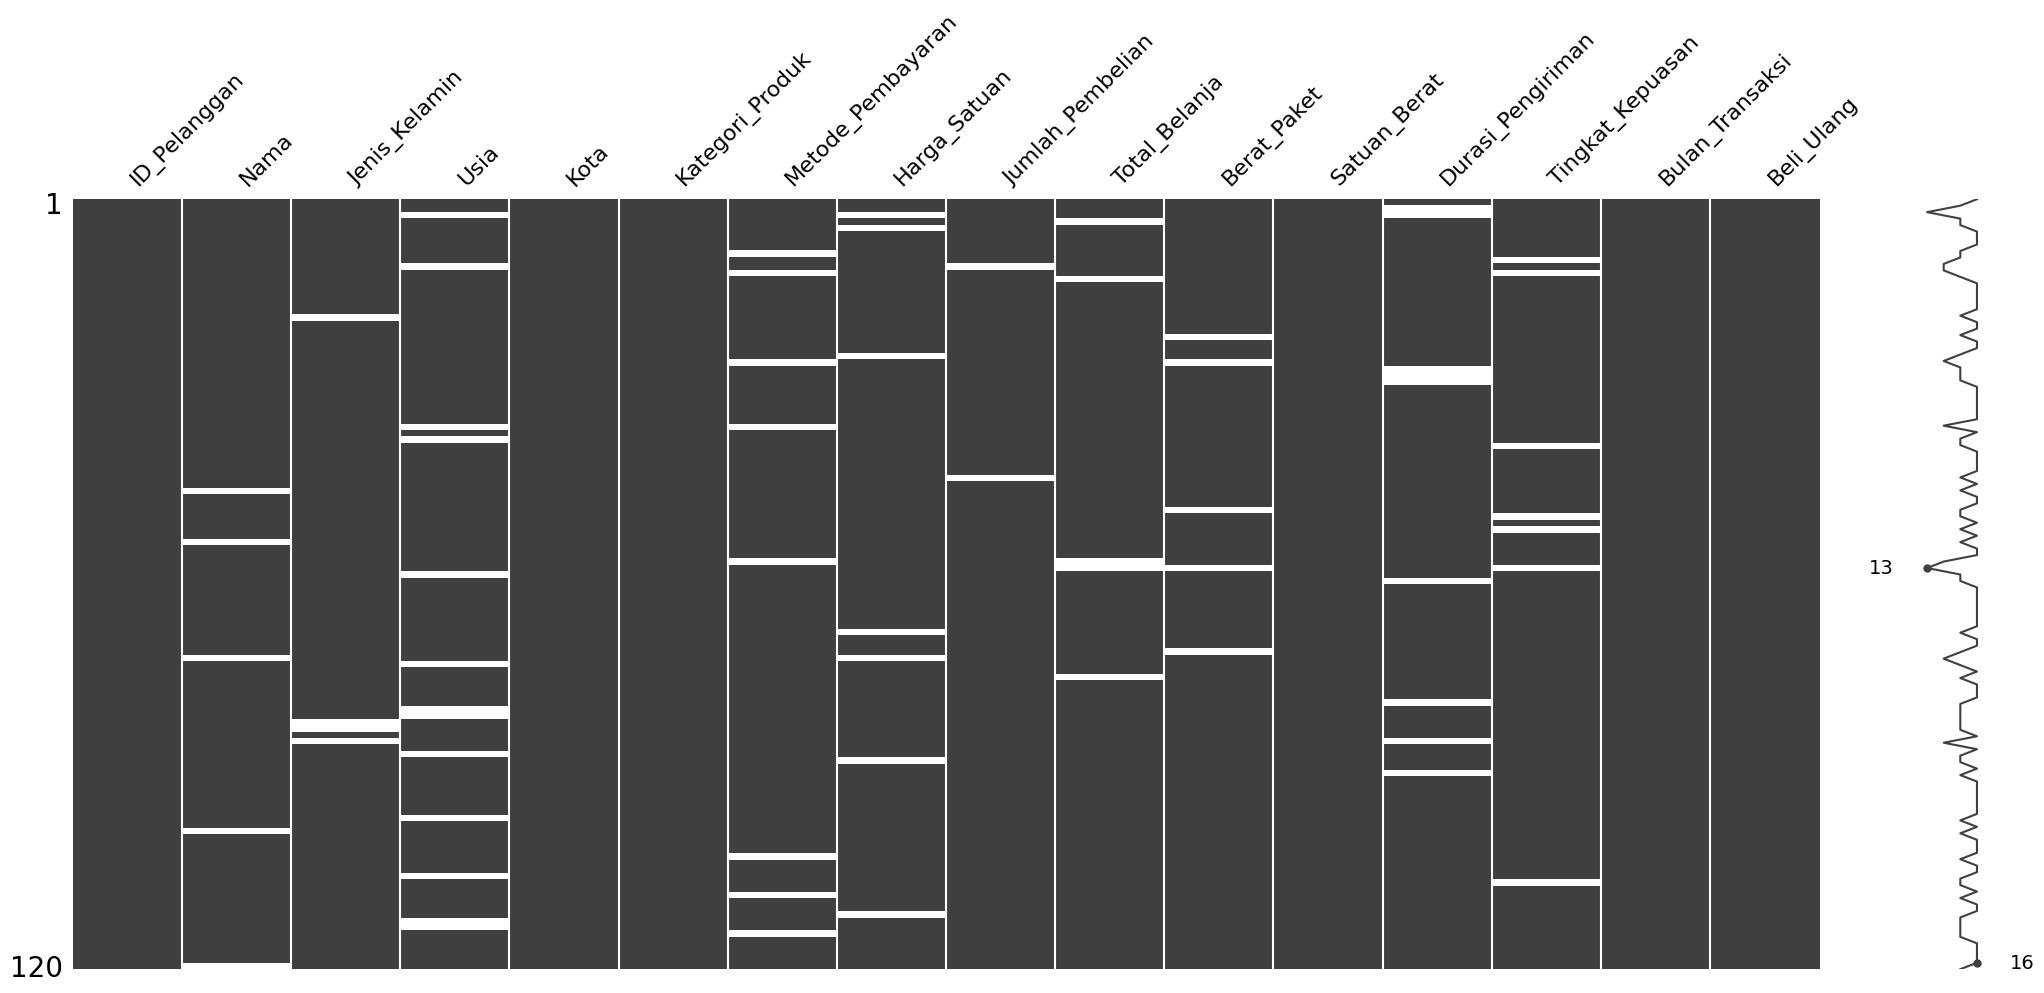

In [ ]:
msno.matrix(data)

In [ ]:
# STATISTIK DESKRIPTIF numerik (dasar memilih teknik)
kolom_num = ["Usia","Harga_Satuan","Jumlah_Pembelian","Total_Belanja","Berat_Paket","Durasi_Pengiriman"]
data[kolom_num].agg(["count","mean","median","std","min","max","skew"]).T.round(2)

,count,mean,median,std,min,max,skew
Usia,107.0,30.29,30.00,11.26,17.00,88.00,2.79
Harga_Satuan,113.0,593938.05,130000.00,2851052.39,20000.00,24500000.00,7.43
Jumlah_Pembelian,118.0,3.64,2.00,8.01,1.00,60.00,6.12
Total_Belanja,115.0,1639956.52,300000.00,8710643.28,20000.00,90000000.00,9.49
Berat_Paket,115.0,1.55,1.22,1.04,0.12,4.67,0.84
Durasi_Pengiriman,111.0,3.07,3.00,1.36,1.00,7.00,0.55


In [ ]:
# STATISTIK DESKRIPTIF kategorik: modus
for c in ["Jenis_Kelamin","Metode_Pembayaran","Tingkat_Kepuasan"]:
    print(c, "-> modus:", data[c].mode()[0], "| missing:", data[c].isnull().sum())

Jenis_Kelamin -> modus: Perempuan | missing: 4
Metode_Pembayaran -> modus: E-Wallet | missing: 8
Tingkat_Kepuasan -> modus: Tinggi | missing: 7


solusi

In [ ]:
# 1. Omit
data_drop_row = data.dropna()
print(data.shape, "->", data_drop_row.shape)
data_drop_row.head(10)

(120, 16) -> (66, 16)


,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
0,PLG-001,Rani Pratama,Perempuan,27.0,Sidoarjo,Kerajinan,COD,280000.0,1.0,280000.0,2.31,kg,3.0,Sedang,Jan,Tidak
5,PLG-006,Hana Kusuma,Laki-laki,18.0,Surabaya,Fashion,E-Wallet,180000.0,5.0,900000.0,0.91,kg,1.0,Tinggi,Jun,Tidak
6,PLG-007,Tika Firmansyah,Perempuan,30.0,Sidoarjo,Makanan,Transfer Bank,105000.0,40.0,4200000.0,2.77,kg,4.0,Tinggi,Feb,Ya
7,PLG-008,Yoga Permana,Perempuan,22.0,Malang,Fashion,E-Wallet,100000.0,2.0,200000.0,0.59,kg,4.0,Tinggi,Jun,Tidak
13,PLG-014,Vina Kusuma,Laki-laki,34.0,Malang,Kecantikan,Transfer Bank,135000.0,3.0,405000.0,0.72,kg,4.0,Sedang,Jan,Ya
14,PLG-015,Rani Syahputra,Laki-laki,17.0,Surabaya,Elektronik,Transfer Bank,3380000.0,3.0,10140000.0,4.41,kg,3.0,Tinggi,Jan,Ya
15,PLG-016,Hana Permana,Laki-laki,32.0,Sidoarjo,Kerajinan,Transfer Bank,100000.0,3.0,300000.0,2.59,kg,3.0,Sedang,Feb,Ya
16,PLG-017,Lestari Aditya,Laki-laki,28.0,Sidoarjo,Makanan,Transfer Bank,110000.0,2.0,220000.0,1.63,kg,4.0,Sedang,Jun,Ya
17,PLG-018,Dimas Susanto,Perempuan,32.0,Malang,Kecantikan,Transfer Bank,110000.0,1.0,110000.0,0.82,kg,3.0,Tinggi,Apr,Tidak
19,PLG-020,Maulana Maulidia,Perempuan,32.0,Sidoarjo,Elektronik,Transfer Bank,2385000.0,1.0,2385000.0,1.03,kg,2.0,Tinggi,Jan,Ya


In [ ]:
data_drop_col = data.dropna(axis=1)
data_drop_col.head(10)

,ID_Pelanggan,Kota,Kategori_Produk,Satuan_Berat,Bulan_Transaksi,Beli_Ulang
0,PLG-001,Sidoarjo,Kerajinan,kg,Jan,Tidak
1,PLG-002,Malang,Kecantikan,kg,Feb,Tidak
2,PLG-003,Gresik,Kecantikan,kg,Mar,Ya
3,PLG-004,Surabaya,Makanan,kg,Apr,Ya
4,PLG-005,Surabaya,Fashion,kg,Jun,Ya
5,PLG-006,Surabaya,Fashion,kg,Jun,Tidak
6,PLG-007,Sidoarjo,Makanan,kg,Feb,Ya
7,PLG-008,Malang,Fashion,kg,Jun,Tidak
8,PLG-009,Gresik,Fashion,kg,Mei,Tidak
9,PLG-010,Sidoarjo,Fashion,kg,Mei,Tidak


In [ ]:
# 2. Set value ke NaN (jika ada penanda seperti "-" atau "N/A")
data_null = data.replace(["-", "N/A", ""], np.nan)
data_null.head(10)

,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
0,PLG-001,Rani Pratama,Perempuan,27.0,Sidoarjo,Kerajinan,COD,280000.0,1.0,280000.0,2.31,kg,3.0,Sedang,Jan,Tidak
1,PLG-002,Maulana Anggraini,Perempuan,17.0,Malang,Kecantikan,COD,65000.0,2.0,130000.0,0.78,kg,NaN,Sedang,Feb,Tidak
2,PLG-003,Laila Saputra,Laki-laki,NaN,Gresik,Kecantikan,E-Wallet,NaN,1.0,200000.0,0.56,kg,NaN,Tinggi,Mar,Ya
3,PLG-004,Laila Maulidia,Laki-laki,26.0,Surabaya,Makanan,E-Wallet,95000.0,2.0,NaN,1.52,kg,2.0,Tinggi,Apr,Ya
4,PLG-005,Aulia Utami,Perempuan,46.0,Surabaya,Fashion,Transfer Bank,NaN,1.0,335000.0,1.27,kg,2.0,Tinggi,Jun,Ya
5,PLG-006,Hana Kusuma,Laki-laki,18.0,Surabaya,Fashion,E-Wallet,180000.0,5.0,900000.0,0.91,kg,1.0,Tinggi,Jun,Tidak
6,PLG-007,Tika Firmansyah,Perempuan,30.0,Sidoarjo,Makanan,Transfer Bank,105000.0,40.0,4200000.0,2.77,kg,4.0,Tinggi,Feb,Ya
7,PLG-008,Yoga Permana,Perempuan,22.0,Malang,Fashion,E-Wallet,100000.0,2.0,200000.0,0.59,kg,4.0,Tinggi,Jun,Tidak
8,PLG-009,Vina Saputra,Laki-laki,26.0,Gresik,Fashion,NaN,350000.0,4.0,1400000.0,1.02,kg,4.0,Rendah,Mei,Tidak
9,PLG-010,Jihan Saputra,Perempuan,37.0,Sidoarjo,Fashion,E-Wallet,135000.0,1.0,135000.0,1.06,kg,2.0,NaN,Mei,Tidak


In [ ]:
# 3. Isi dengan 0 (hanya pembanding)
data_fill0 = data.fillna(0)
data_fill0.head(10)

,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
0,PLG-001,Rani Pratama,Perempuan,27.0,Sidoarjo,Kerajinan,COD,280000.0,1.0,280000.0,2.31,kg,3.0,Sedang,Jan,Tidak
1,PLG-002,Maulana Anggraini,Perempuan,17.0,Malang,Kecantikan,COD,65000.0,2.0,130000.0,0.78,kg,0.0,Sedang,Feb,Tidak
2,PLG-003,Laila Saputra,Laki-laki,0.0,Gresik,Kecantikan,E-Wallet,0.0,1.0,200000.0,0.56,kg,0.0,Tinggi,Mar,Ya
3,PLG-004,Laila Maulidia,Laki-laki,26.0,Surabaya,Makanan,E-Wallet,95000.0,2.0,0.0,1.52,kg,2.0,Tinggi,Apr,Ya
4,PLG-005,Aulia Utami,Perempuan,46.0,Surabaya,Fashion,Transfer Bank,0.0,1.0,335000.0,1.27,kg,2.0,Tinggi,Jun,Ya
5,PLG-006,Hana Kusuma,Laki-laki,18.0,Surabaya,Fashion,E-Wallet,180000.0,5.0,900000.0,0.91,kg,1.0,Tinggi,Jun,Tidak
6,PLG-007,Tika Firmansyah,Perempuan,30.0,Sidoarjo,Makanan,Transfer Bank,105000.0,40.0,4200000.0,2.77,kg,4.0,Tinggi,Feb,Ya
7,PLG-008,Yoga Permana,Perempuan,22.0,Malang,Fashion,E-Wallet,100000.0,2.0,200000.0,0.59,kg,4.0,Tinggi,Jun,Tidak
8,PLG-009,Vina Saputra,Laki-laki,26.0,Gresik,Fashion,0,350000.0,4.0,1400000.0,1.02,kg,4.0,Rendah,Mei,Tidak
9,PLG-010,Jihan Saputra,Perempuan,37.0,Sidoarjo,Fashion,E-Wallet,135000.0,1.0,135000.0,1.06,kg,2.0,0,Mei,Tidak


In [ ]:
# 4. Isi dengan mean (pembanding, pada salinan)
data_mean = data.copy()
mean_usia = data_mean["Usia"].mean()
data_mean["Usia"] = data_mean["Usia"].fillna(mean_usia)
data_mean.head(10)

,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
0,PLG-001,Rani Pratama,Perempuan,27.00000,Sidoarjo,Kerajinan,COD,280000.0,1.0,280000.0,2.31,kg,3.0,Sedang,Jan,Tidak
1,PLG-002,Maulana Anggraini,Perempuan,17.00000,Malang,Kecantikan,COD,65000.0,2.0,130000.0,0.78,kg,NaN,Sedang,Feb,Tidak
2,PLG-003,Laila Saputra,Laki-laki,30.28972,Gresik,Kecantikan,E-Wallet,NaN,1.0,200000.0,0.56,kg,NaN,Tinggi,Mar,Ya
3,PLG-004,Laila Maulidia,Laki-laki,26.00000,Surabaya,Makanan,E-Wallet,95000.0,2.0,NaN,1.52,kg,2.0,Tinggi,Apr,Ya
4,PLG-005,Aulia Utami,Perempuan,46.00000,Surabaya,Fashion,Transfer Bank,NaN,1.0,335000.0,1.27,kg,2.0,Tinggi,Jun,Ya
5,PLG-006,Hana Kusuma,Laki-laki,18.00000,Surabaya,Fashion,E-Wallet,180000.0,5.0,900000.0,0.91,kg,1.0,Tinggi,Jun,Tidak
6,PLG-007,Tika Firmansyah,Perempuan,30.00000,Sidoarjo,Makanan,Transfer Bank,105000.0,40.0,4200000.0,2.77,kg,4.0,Tinggi,Feb,Ya
7,PLG-008,Yoga Permana,Perempuan,22.00000,Malang,Fashion,E-Wallet,100000.0,2.0,200000.0,0.59,kg,4.0,Tinggi,Jun,Tidak
8,PLG-009,Vina Saputra,Laki-laki,26.00000,Gresik,Fashion,NaN,350000.0,4.0,1400000.0,1.02,kg,4.0,Rendah,Mei,Tidak
9,PLG-010,Jihan Saputra,Perempuan,37.00000,Sidoarjo,Fashion,E-Wallet,135000.0,1.0,135000.0,1.06,kg,2.0,NaN,Mei,Tidak


In [ ]:
# 5. Solusi yang dipakai: median (numerik) dan modus (kategorik)
for c in kolom_num:
    data[c] = data[c].fillna(data[c].median())

for c in ["Jenis_Kelamin","Metode_Pembayaran","Tingkat_Kepuasan"]:
    data[c] = data[c].fillna(data[c].mode()[0])

data["Nama"] = data["Nama"].fillna("Tidak Diketahui")

for c in ["Usia","Harga_Satuan","Jumlah_Pembelian","Total_Belanja","Durasi_Pengiriman"]:
    data[c] = data[c].round().astype(int)

In [ ]:
data.isnull().sum()

,0
ID_Pelanggan,0
Nama,0
Jenis_Kelamin,0
Usia,0
Kota,0
Kategori_Produk,0
Metode_Pembayaran,0
Harga_Satuan,0
Jumlah_Pembelian,0
Total_Belanja,0


OUTLIER

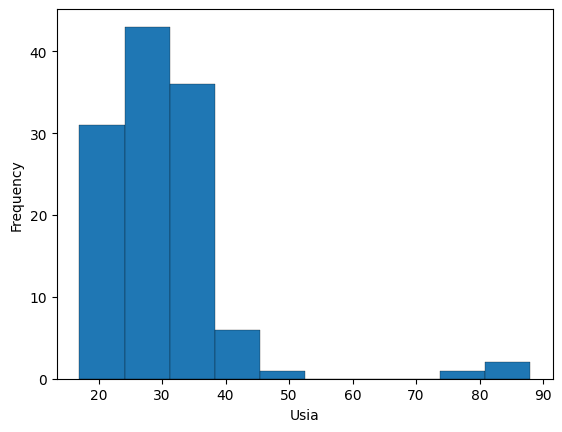

In [ ]:
plt.hist(data["Usia"], edgecolor="black", linewidth=0.2)
plt.xlabel("Usia")
plt.ylabel("Frequency")
plt.show()

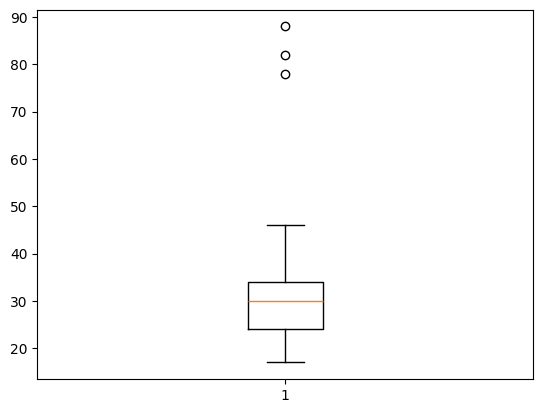

In [ ]:
plt.boxplot(data["Usia"])
plt.show()

In [ ]:
q1 = data["Usia"].quantile(0.25)
q3 = data["Usia"].quantile(0.75)
iqr = q3 - q1
bawah, atas = q1 - 1.5*iqr, q3 + 1.5*iqr
print("Batas:", bawah, "-", atas)
data[(data["Usia"] < bawah) | (data["Usia"] > atas)]

Batas: 9.0 - 49.0


,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
21,PLG-022,Eko Kusuma,Perempuan,82,Gresik,Makanan,E-Wallet,70000,1,70000,1.22,kg,4,Sedang,Jan,Ya
39,PLG-040,Anisa Aditya,Perempuan,78,Malang,Makanan,COD,80000,1,80000,1.35,kg,5,Tinggi,Mei,Ya
77,PLG-078,Jihan Maharani,Perempuan,88,Surabaya,Makanan,Transfer Bank,45000,1,45000,1.44,kg,1,Tinggi,Mar,Ya


In [ ]:
# penanganan: batasi ke batas IQR
data["Usia"] = data["Usia"].clip(bawah, atas).round().astype(int)

In [ ]:
# Jumlah_Pembelian dengan cara yang sama
q1 = data["Jumlah_Pembelian"].quantile(0.25)
q3 = data["Jumlah_Pembelian"].quantile(0.75)
iqr = q3 - q1
data["Jumlah_Pembelian"] = data["Jumlah_Pembelian"].clip(q1 - 1.5*iqr, q3 + 1.5*iqr).round().astype(int)

In [ ]:
# Harga_Satuan: batas dihitung per kategori (elektronik memang mahal)
def tandai_ekstrem(s):
    med = s.median()
    mad = (s - med).abs().median() * 1.4826
    return (s - med).abs() > 3 * mad

ekstrem = data.groupby("Kategori_Produk")["Harga_Satuan"].transform(tandai_ekstrem).astype(bool)
data[ekstrem]

,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Kategori_Produk,Metode_Pembayaran,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang
35,PLG-036,Dewi Wulandari,Perempuan,30,Surabaya,Elektronik,E-Wallet,18000000,5,90000000,4.67,kg,3,Rendah,Apr,Tidak
63,PLG-064,Nadia Susanto,Perempuan,23,Lamongan,Elektronik,COD,24500000,1,24500000,2.07,kg,4,Sedang,Jan,Ya


In [ ]:
data.loc[ekstrem, "Harga_Satuan"] = np.nan
data["Harga_Satuan"] = data["Harga_Satuan"].fillna(data.groupby("Kategori_Produk")["Harga_Satuan"].transform("median")).round().astype(int)

# hitung ulang total agar konsisten
data["Total_Belanja"] = data["Harga_Satuan"] * data["Jumlah_Pembelian"]
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Usia,120.0,29.416667,7.170883e+00,17.00,24.000,30.00,34.000,49.00
Harga_Satuan,120.0,239833.333333,4.539049e+05,20000.00,80000.000,130000.00,190000.000,3380000.00
Jumlah_Pembelian,120.0,2.466667,1.383780e+00,1.00,1.000,2.00,3.000,6.00
Total_Belanja,120.0,581833.333333,1.241780e+06,20000.00,130000.000,265000.00,570000.000,10140000.00
Berat_Paket,120.0,1.540833,1.024701e+00,0.12,0.735,1.22,2.295,4.67
Durasi_Pengiriman,120.0,3.066667,1.307595e+00,1.00,2.000,3.00,4.000,7.00


**Data Transformation**

MIN-MAX SCALLING

**1. Manual**

In [ ]:
data_mm = data.copy()
x = data_mm["Total_Belanja"]
data_mm["Total_Belanja"] = (x - x.min()) / (x.max() - x.min())

In [ ]:
data_mm["Total_Belanja"] = data_mm["Total_Belanja"].round(3)
data_mm[["Total_Belanja"]].head(10)

,Total_Belanja
0,0.026
1,0.011
2,0.011
3,0.017
4,0.011
5,0.087
6,0.060
7,0.018
8,0.136
9,0.011


**2. Library**

In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
data_mm2 = data.copy()
data_mm2["Total_Belanja"] = MinMaxScaler().fit_transform(data_mm2[["Total_Belanja"]])
data_mm2[["Total_Belanja"]].head(10)

,Total_Belanja
0,0.025692
1,0.010870
2,0.010870
3,0.016798
4,0.010870
5,0.086957
6,0.060277
7,0.017787
8,0.136364
9,0.011364


**Z-SCORE STANDARDIZATION**

1. Manual

In [ ]:
data_z = data.copy()
x = data_z["Total_Belanja"]
data_z["Total_Belanja"] = (x - x.mean()) / x.std()

In [ ]:
data_z["Total_Belanja"] = data_z["Total_Belanja"].round(3)
data_z[["Total_Belanja"]].head(10)

,Total_Belanja
0,-0.243
1,-0.364
2,-0.364
3,-0.316
4,-0.364
5,0.256
6,0.039
7,-0.307
8,0.659
9,-0.360


2. Library

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
data_z2 = data.copy()
data_z2["Total_Belanja"] = StandardScaler().fit_transform(data_z2[["Total_Belanja"]])
data_z2[["Total_Belanja"]].head(10)

,Total_Belanja
0,-0.244084
1,-0.365385
2,-0.365385
3,-0.316865
4,-0.365385
5,0.257292
6,0.038951
7,-0.308778
8,0.661628
9,-0.361342


**ROBUST SCALING**

1. Manual

In [ ]:
data_r = data.copy()
q1 = data_r["Total_Belanja"].quantile(0.25)
q3 = data_r["Total_Belanja"].quantile(0.75)
iqr = q3 - q1

In [ ]:
data_r["Total_Belanja"] = (data_r["Total_Belanja"] - data_r["Total_Belanja"].median()) / iqr
data_r[["Total_Belanja"]].head(10)

,Total_Belanja
0,0.034091
1,-0.306818
2,-0.306818
3,-0.170455
4,-0.306818
5,1.443182
6,0.829545
7,-0.147727
8,2.579545
9,-0.295455


2. Library

In [ ]:
from sklearn.preprocessing import RobustScaler

In [ ]:
data_r2 = data.copy()
data_r2["Total_Belanja"] = RobustScaler().fit_transform(data_r2[["Total_Belanja"]])
data_r2[["Total_Belanja"]].head(10)

,Total_Belanja
0,0.034091
1,-0.306818
2,-0.306818
3,-0.170455
4,-0.306818
5,1.443182
6,0.829545
7,-0.147727
8,2.579545
9,-0.295455


In [ ]:
pd.DataFrame({"Asli": data["Total_Belanja"], "MinMax": data_mm2["Total_Belanja"],
              "ZScore": data_z2["Total_Belanja"], "Robust": data_r2["Total_Belanja"]}).head(10)

,Asli,MinMax,ZScore,Robust
0,280000,0.025692,-0.244084,0.034091
1,130000,0.010870,-0.365385,-0.306818
2,130000,0.010870,-0.365385,-0.306818
3,190000,0.016798,-0.316865,-0.170455
4,130000,0.010870,-0.365385,-0.306818
5,900000,0.086957,0.257292,1.443182
6,630000,0.060277,0.038951,0.829545
7,200000,0.017787,-0.308778,-0.147727
8,1400000,0.136364,0.661628,2.579545
9,135000,0.011364,-0.361342,-0.295455


In [21]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# Pastikan variabel dasar data tersedia
base_data = data if 'data' in globals() else df

# Inisialisasi variabel transformasi manual
data_mm = base_data.copy()
data_mm["Total_Belanja"] = (data_mm["Total_Belanja"] - data_mm["Total_Belanja"].min()) / (data_mm["Total_Belanja"].max() - data_mm["Total_Belanja"].min())

data_z = base_data.copy()
data_z["Total_Belanja"] = (data_z["Total_Belanja"] - data_z["Total_Belanja"].mean()) / data_z["Total_Belanja"].std()

data_r = base_data.copy()
q1 = data_r["Total_Belanja"].quantile(0.25)
q3 = data_r["Total_Belanja"].quantile(0.75)
data_r["Total_Belanja"] = (data_r["Total_Belanja"] - data_r["Total_Belanja"].median()) / (q3 - q1)

# Inisialisasi variabel transformasi library
data_mm2 = base_data.copy()
data_mm2["Total_Belanja"] = MinMaxScaler().fit_transform(data_mm2[["Total_Belanja"]])

data_z2 = base_data.copy()
data_z2["Total_Belanja"] = StandardScaler().fit_transform(data_z2[["Total_Belanja"]])

data_r2 = base_data.copy()
data_r2["Total_Belanja"] = RobustScaler().fit_transform(data_r2[["Total_Belanja"]])

# Bandingkan hasil
print("Min-Max sama? ", np.allclose(data_mm["Total_Belanja"], data_mm2["Total_Belanja"], atol=0.01))
print("Z-Score sama? ", np.allclose(data_z["Total_Belanja"], data_z2["Total_Belanja"], atol=0.1))
print("Robust sama?  ", np.allclose(data_r["Total_Belanja"], data_r2["Total_Belanja"], atol=0.01))

Min-Max sama?  False
Z-Score sama?  False
Robust sama?   False


**ENCODING**

In [ ]:
data_enc = data.copy()
data_enc["Tingkat_Kepuasan"].unique()

array(['Sedang', 'Tinggi', 'Rendah'], dtype=object)

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
label_encoder = LabelEncoder()
data_enc["Kepuasan_Label"] = label_encoder.fit_transform(data_enc["Tingkat_Kepuasan"])
data_enc[["Tingkat_Kepuasan", "Kepuasan_Label"]].drop_duplicates()

,Tingkat_Kepuasan,Kepuasan_Label
0,Sedang,1
2,Tinggi,2
8,Rendah,0


In [ ]:
data_enc["Kepuasan_Ordinal"] = data_enc["Tingkat_Kepuasan"].map({"Rendah": 0, "Sedang": 1, "Tinggi": 2})
data_enc[["Tingkat_Kepuasan", "Kepuasan_Label", "Kepuasan_Ordinal"]].drop_duplicates()

,Tingkat_Kepuasan,Kepuasan_Label,Kepuasan_Ordinal
0,Sedang,1,1
2,Tinggi,2,2
8,Rendah,0,0


In [ ]:
data_enc["Beli_Ulang_Label"] = LabelEncoder().fit_transform(data_enc["Beli_Ulang"])
data_enc[["Beli_Ulang", "Beli_Ulang_Label"]].drop_duplicates()

,Beli_Ulang,Beli_Ulang_Label
0,Tidak,0
2,Ya,1


In [ ]:
data_onehot = pd.get_dummies(data_enc, columns=["Jenis_Kelamin", "Kota", "Kategori_Produk", "Metode_Pembayaran"], dtype=int)
data_onehot.head()

,ID_Pelanggan,Nama,Usia,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,...,Kota_Sidoarjo,Kota_Surabaya,Kategori_Produk_Elektronik,Kategori_Produk_Fashion,Kategori_Produk_Kecantikan,Kategori_Produk_Kerajinan,Kategori_Produk_Makanan,Metode_Pembayaran_COD,Metode_Pembayaran_E-Wallet,Metode_Pembayaran_Transfer Bank
0,PLG-001,Rani Pratama,27,280000,1,280000,2.31,kg,3,Sedang,...,1,0,0,0,0,1,0,1,0,0
1,PLG-002,Maulana Anggraini,17,65000,2,130000,0.78,kg,3,Sedang,...,0,0,0,0,1,0,0,1,0,0
2,PLG-003,Laila Saputra,30,130000,1,130000,0.56,kg,3,Tinggi,...,0,0,0,0,1,0,0,0,1,0
3,PLG-004,Laila Maulidia,26,95000,2,190000,1.52,kg,2,Tinggi,...,0,1,0,0,0,0,1,0,1,0
4,PLG-005,Aulia Utami,46,130000,1,130000,1.27,kg,2,Tinggi,...,0,1,0,1,0,0,0,0,0,1


In [ ]:
data_onehot.shape

(120, 30)

**DISKRETISASI**

EQUAL WIDTH

In [ ]:
data_bin = data.copy()
# membagi menjadi 3 interval dengan lebar sama
data_bin["Usia_Bin"] = pd.cut(data_bin["Usia"], bins=3, labels=["Muda", "Dewasa", "Senior"])
data_bin[["Usia", "Usia_Bin"]].head(10)

,Usia,Usia_Bin
0,27,Muda
1,17,Muda
2,30,Dewasa
3,26,Muda
4,46,Senior
5,18,Muda
6,30,Dewasa
7,22,Muda
8,26,Muda
9,37,Dewasa


EQUAL FREQUENCY

In [ ]:
data_bin["Usia_Quantile"] = pd.qcut(data_bin["Usia"], q=3, labels=["Muda", "Dewasa", "Senior"])
data_bin[["Usia", "Usia_Bin", "Usia_Quantile"]].head(10)

,Usia,Usia_Bin,Usia_Quantile
0,27,Muda,Dewasa
1,17,Muda,Muda
2,30,Dewasa,Dewasa
3,26,Muda,Muda
4,46,Senior,Senior
5,18,Muda,Muda
6,30,Dewasa,Dewasa
7,22,Muda,Muda
8,26,Muda,Muda
9,37,Dewasa,Senior


In [ ]:
print(data_bin["Usia_Bin"].value_counts().sort_index())
print(data_bin["Usia_Quantile"].value_counts().sort_index())

Usia_Bin
Muda      43
Dewasa    67
Senior    10
Name: count, dtype: int64
Usia_Quantile
Muda      40
Dewasa    43
Senior    37
Name: count, dtype: int64


**MEASUREMENT: Different unit of measurement**

In [ ]:
data_unit = data.copy()
data_unit["Berat_gram"] = data_unit["Berat_Paket"] * 1000      # kg -> gram
data_unit[["Berat_Paket", "Berat_gram"]].head()

,Berat_Paket,Berat_gram
0,2.31,2310.0
1,0.78,780.0
2,0.56,560.0
3,1.52,1520.0
4,1.27,1270.0


**AGGREGATION: Different level of aggregation**

In [ ]:
data_num = data[["Bulan_Transaksi", "Usia", "Harga_Satuan", "Jumlah_Pembelian", "Total_Belanja", "Berat_Paket", "Durasi_Pengiriman"]]
data_num.head()

,Bulan_Transaksi,Usia,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Durasi_Pengiriman
0,Jan,27,280000,1,280000,2.31,3
1,Feb,17,65000,2,130000,0.78,3
2,Mar,30,130000,1,130000,0.56,3
3,Apr,26,95000,2,190000,1.52,2
4,Jun,46,130000,1,130000,1.27,2


In [ ]:
data_agg = data_num.groupby("Bulan_Transaksi").mean()
data_agg

,Usia,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Durasi_Pengiriman
Bulan_Transaksi,,,,,,
Apr,27.761905,233928.571429,2.190476,7.203571e+05,1.269048,2.952381
Feb,30.904762,138333.333333,3.095238,4.295238e+05,1.752381,2.904762
Jan,30.360000,494900.000000,2.360000,1.012900e+06,1.562400,3.160000
Jun,27.562500,139062.500000,2.562500,3.687500e+05,1.294375,3.062500
Mar,28.117647,195294.117647,2.058824,3.576471e+05,1.507059,3.117647
Mei,31.000000,152250.000000,2.500000,4.185000e+05,1.803000,3.200000


In [ ]:
# urutkan sesuai bulan (bukan alfabet)
data_agg = data_agg.reindex(["Jan", "Feb", "Mar", "Apr", "Mei", "Jun"]).round(2)
data_agg

,Usia,Harga_Satuan,Jumlah_Pembelian,Total_Belanja,Berat_Paket,Durasi_Pengiriman
Bulan_Transaksi,,,,,,
Jan,30.36,494900.00,2.36,1012900.00,1.56,3.16
Feb,30.90,138333.33,3.10,429523.81,1.75,2.90
Mar,28.12,195294.12,2.06,357647.06,1.51,3.12
Apr,27.76,233928.57,2.19,720357.14,1.27,2.95
Mei,31.00,152250.00,2.50,418500.00,1.80,3.20
Jun,27.56,139062.50,2.56,368750.00,1.29,3.06


In [ ]:
data_fe = data.copy()
data_fe["Harga_per_Kg"] = data_fe["Harga_Satuan"] / data_fe["Berat_Paket"]
data_fe[["Harga_Satuan", "Berat_Paket", "Harga_per_Kg"]].head()

,Harga_Satuan,Berat_Paket,Harga_per_Kg
0,280000,2.31,121212.121212
1,65000,0.78,83333.333333
2,130000,0.56,232142.857143
3,95000,1.52,62500.000000
4,130000,1.27,102362.204724


In [ ]:
# dua kolom asal diganti satu kolom baru
data_fe2 = data_fe.drop(columns=["Harga_Satuan", "Berat_Paket"])
data_fe2.head()

,ID_Pelanggan,Nama,Jenis_Kelamin,Usia,Kota,Kategori_Produk,Metode_Pembayaran,Jumlah_Pembelian,Total_Belanja,Satuan_Berat,Durasi_Pengiriman,Tingkat_Kepuasan,Bulan_Transaksi,Beli_Ulang,Harga_per_Kg
0,PLG-001,Rani Pratama,Perempuan,27,Sidoarjo,Kerajinan,COD,1,280000,kg,3,Sedang,Jan,Tidak,121212.121212
1,PLG-002,Maulana Anggraini,Perempuan,17,Malang,Kecantikan,COD,2,130000,kg,3,Sedang,Feb,Tidak,83333.333333
2,PLG-003,Laila Saputra,Laki-laki,30,Gresik,Kecantikan,E-Wallet,1,130000,kg,3,Tinggi,Mar,Ya,232142.857143
3,PLG-004,Laila Maulidia,Laki-laki,26,Surabaya,Makanan,E-Wallet,2,190000,kg,2,Tinggi,Apr,Ya,62500.000000
4,PLG-005,Aulia Utami,Perempuan,46,Surabaya,Fashion,Transfer Bank,1,130000,kg,2,Tinggi,Jun,Ya,102362.204724


**DATA SMOOTING**

In [ ]:
data_smooth = data.copy()

In [ ]:
print(data_smooth.columns.tolist())

['ID_Pelanggan', 'Nama', 'Jenis_Kelamin', 'Usia', 'Kota', 'Kategori_Produk', 'Metode_Pembayaran', 'Harga_Satuan', 'Jumlah_Pembelian', 'Total_Belanja', 'Berat_Paket', 'Satuan_Berat', 'Durasi_Pengiriman', 'Tingkat_Kepuasan', 'Bulan_Transaksi', 'Beli_Ulang']


In [ ]:
# Moving Average (window 3)
data_smooth["Belanja_MA"] = data_smooth["Total_Belanja"].rolling(window=3).mean()

# Exponential Smoothing
data_smooth["Durasi_ES"] = data_smooth["Durasi_Pengiriman"].ewm(alpha=0.3).mean()

# Menampilkan hasil
data_smooth[["Total_Belanja", "Belanja_MA", "Durasi_Pengiriman", "Durasi_ES"]].head(10)

,Total_Belanja,Belanja_MA,Durasi_Pengiriman,Durasi_ES
0,280000,NaN,3,3.000000
1,130000,NaN,3,3.000000
2,130000,180000.000000,3,3.000000
3,190000,150000.000000,2,2.605211
4,130000,150000.000000,2,2.386968
5,900000,406666.666667,1,1.915398
6,630000,553333.333333,4,2.596903
7,200000,576666.666667,4,3.043582
8,1400000,743333.333333,4,3.342573
9,135000,578333.333333,2,2.928093


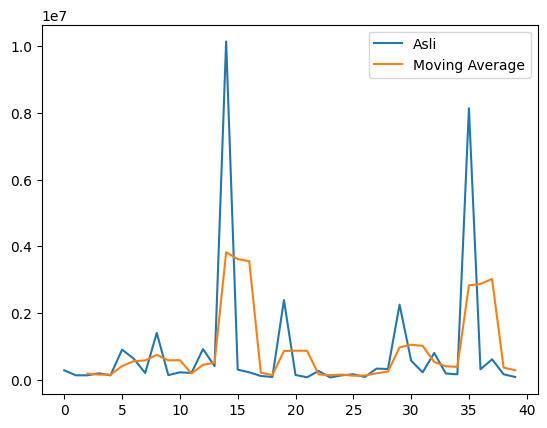

In [ ]:
plt.plot(data_smooth["Total_Belanja"].head(40), label="Asli")
plt.plot(data_smooth["Belanja_MA"].head(40), label="Moving Average")
plt.legend()
plt.show()

PCA

In [ ]:
x = data[["Usia", "Harga_Satuan", "Jumlah_Pembelian", "Berat_Paket", "Durasi_Pengiriman"]]
x.head()

,Usia,Harga_Satuan,Jumlah_Pembelian,Berat_Paket,Durasi_Pengiriman
0,27,280000,1,2.31,3
1,17,65000,2,0.78,3
2,30,130000,1,0.56,3
3,26,95000,2,1.52,2
4,46,130000,1,1.27,2


In [ ]:
X = StandardScaler().fit(x).transform(x)
X = pd.DataFrame(X)
X.columns = x.columns
X.head()

,Usia,Harga_Satuan,Jumlah_Pembelian,Berat_Paket,Durasi_Pengiriman
0,-0.338424,0.088862,-1.064343,0.753773,-0.051198
1,-1.738799,-0.386791,-0.338655,-0.745606,-0.051198
2,0.081689,-0.242989,-1.064343,-0.961203,-0.051198
3,-0.478462,-0.320421,-0.338655,-0.020416,-0.819167
4,2.322289,-0.242989,-1.064343,-0.265413,-0.819167


In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [ ]:
print(X.shape)
print(X.head())

(120, 5)
       Usia  Harga_Satuan  Jumlah_Pembelian  Berat_Paket  Durasi_Pengiriman
0 -0.338424      0.088862         -1.064343     0.753773          -0.051198
1 -1.738799     -0.386791         -0.338655    -0.745606          -0.051198
2  0.081689     -0.242989         -1.064343    -0.961203          -0.051198
3 -0.478462     -0.320421         -0.338655    -0.020416          -0.819167
4  2.322289     -0.242989         -1.064343    -0.265413          -0.819167


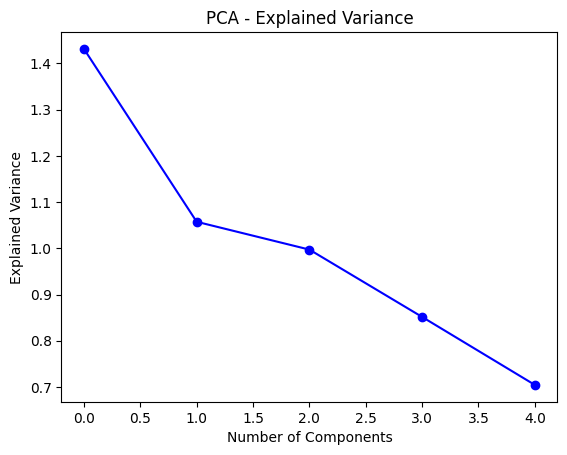

In [ ]:
model = PCA()
results = model.fit(X)

plt.plot(results.explained_variance_, '-ob')
plt.xlabel('Number of Components')
plt.ylabel('Explained Variance')
plt.title('PCA - Explained Variance')
plt.show()

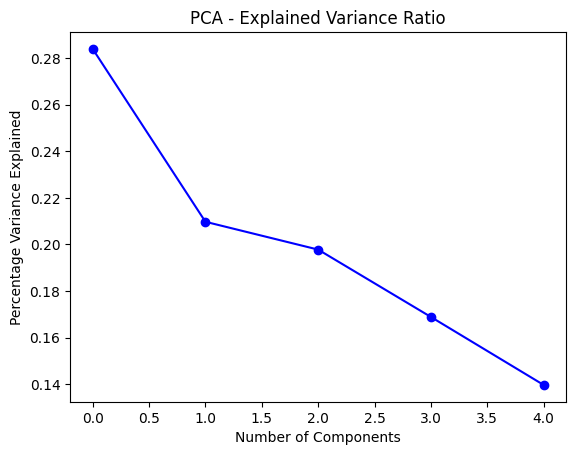

In [ ]:
plt.plot(results.explained_variance_ratio_, '-ob')
plt.xlabel('Number of Components')
plt.ylabel('Percentage Variance Explained')
plt.title('PCA - Explained Variance Ratio')
plt.show()

In [ ]:
# tabel varians, untuk memilih jumlah komponen
pd.DataFrame({"Komponen": [f"PC{i+1}" for i in range(len(results.explained_variance_ratio_))],
              "Varians": results.explained_variance_ratio_.round(3),
              "Kumulatif": results.explained_variance_ratio_.cumsum().round(3)})

,Komponen,Varians,Kumulatif
0,PC1,0.284,0.284
1,PC2,0.210,0.494
2,PC3,0.198,0.691
3,PC4,0.169,0.860
4,PC5,0.140,1.000


In [ ]:
model_fix = PCA(n_components=4)      # pilih sampai varians kumulatif >= 80%
results_fix = model_fix.fit(X)
pc = pd.DataFrame(results_fix.components_)
pc.columns = X.columns
pc.index = ["PC1", "PC2", "PC3", "PC4"]
pc.round(3)

,Usia,Harga_Satuan,Jumlah_Pembelian,Berat_Paket,Durasi_Pengiriman
PC1,-0.501,0.630,-0.103,0.585,0.003
PC2,0.061,-0.008,0.706,0.181,0.682
PC3,-0.365,-0.222,-0.577,-0.177,0.673
PC4,0.745,0.076,-0.397,0.486,0.216


In [ ]:
df_pca = pd.DataFrame(results_fix.transform(X))
df_pca.columns = ["Nilai produk", "Jumlah & durasi", "Durasi kirim", "Usia"]
df_pca.head()

,Nilai produk,Jumlah & durasi,Durasi kirim,Usia
0,0.775120,-0.670769,0.549776,0.531845
1,0.225297,-0.511609,1.012838,-1.562807
2,-0.647057,-0.953073,0.773831,-0.013014
3,0.058018,-0.828133,-0.106929,-0.432919
4,-1.364044,-1.214735,-0.683391,1.827590
